# Phase 3 - three base models and hyperparameter optimisation (Parts E and F)

**Question.** How well do three different model families do, and how much does tuning help each one?

**Brief and report.** Parts E and F. Report Sections 5–6 and Tables 9–12. Training CV only; the test set is not loaded.

The setup cell below makes the repository root the working folder, so `src/` can be imported, and defines two helpers: `results(name)` reads a table from `results/` and `show(...)` displays saved figures from `reports/figures/`.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import Image, Markdown, display
from src.common import ROOT
pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

def show(*names):
    """Display saved figures from reports/figures/."""
    for name in names:
        display(Markdown(f'**reports/figures/{name}**'))
        display(Image(filename=str(ROOT / 'reports' / 'figures' / name)))

def results(name):
    return pd.read_csv(ROOT / 'results' / name)

### 1. Baselines and the three model families
`run_models()` in `src/models.py` runs four stages on the same group-aware folds:
1. Two naive baselines: always predict "not cancelled", and guess at random at the cancellation rate.
2. Logistic regression, random forest and histogram gradient boosting with library defaults.
3. A random search for each family (`RandomizedSearchCV`, with 20, 25 and 40 settings).
4. The tuned model is whichever is better: the best setting or the default.

**How to read the tables.** The baselines show the floor: a model that does not rank at all has AP equal to the cancellation rate.

In [2]:
from src.models import run_models
baselines, tuning, curves = run_models()
display(baselines[['model', 'pr_auc_mean', 'accuracy_mean', 'f1_mean']])
display(results('phase3_baseline.csv')[['model', 'pr_auc_mean', 'pr_auc_std', 'f1_mean', 'train_pr_auc_mean', 'fit_seconds']])

Phase 3 | naive baselines: Majority AP 0.276 (= class rate).


Phase 3 | default: Logistic Regression: CV AP 0.628


Phase 3 | search: Logistic Regression: default 0.628 -> tuned 0.628 (gain +0.0000, 95% CI -0.0003 to +0.0004); 345 s


Phase 3 | default: Random Forest: CV AP 0.672


Phase 3 | search: Random Forest: default 0.672 -> tuned 0.690 (gain +0.0177, 95% CI +0.0123 to +0.0232); 1144 s


Phase 3 | default: Hist Gradient Boosting: CV AP 0.676


... (3 outputs left out)

Phase 3 | validation curve: Hist Gradient Boosting: model__learning_rate


Phase 3 | validation curve: Hist Gradient Boosting: model__max_leaf_nodes


,model,pr_auc_mean,accuracy_mean,f1_mean
0,Majority baseline,0.276,0.724,0.000
1,Stratified baseline,0.274,0.599,0.265


,model,pr_auc_mean,pr_auc_std,f1_mean,train_pr_auc_mean,fit_seconds
0,Logistic Regression,0.628,0.006,0.522,0.631,2.986
1,Random Forest,0.672,0.007,0.579,0.999,16.438
2,Hist Gradient Boosting,0.676,0.006,0.572,0.715,6.949


### 2. Did tuning help?
**How to read the output.**
- `improvement_pr_auc` is tuned minus default CV AP. Its interval uses the Nadeau–Bengio correction, because the folds share most of their training rows.
- `candidates_beating_default` counts how many settings beat the default.
- The validation curves vary one parameter around the chosen setting. A widening gap between training and validation means overfitting.

Notebook 07 checks the gain without the optimism of choosing and scoring on the same folds, and notebook 04 checks it once on the test set.

,model,default_pr_auc,tuned_pr_auc,improvement_pr_auc,improvement_ci_low,improvement_ci_high,improvement_p_value,candidates,candidates_beating_default,chosen,best_params_json,search_seconds
0,Logistic Regression,0.628,0.628,2.502e-05,-3.453e-04,3.953e-04,8.603e-01,20,2,search winner,"{""model__C"": 2.6373339933815254, ""model__class...",345.405
1,Random Forest,0.672,0.690,1.774e-02,1.231e-02,2.317e-02,8.208e-04,25,17,search winner,"{""model__n_estimators"": 200, ""model__min_sampl...",1144.137
2,Hist Gradient Boosting,0.676,0.687,1.146e-02,9.266e-03,1.366e-02,1.319e-04,40,22,search winner,"{""model__l2_regularization"": 0.002259279742015...",1342.228


,model,parameter,value,train_pr_auc,cv_pr_auc,cv_pr_auc_std
0,Logistic Regression,C,0.001,0.608,0.607,0.006
1,Logistic Regression,C,0.005,0.622,0.621,0.005
2,Logistic Regression,C,0.027,0.628,0.626,0.005
3,Logistic Regression,C,0.139,0.630,0.628,0.005
4,Logistic Regression,C,0.720,0.631,0.628,0.005
5,Logistic Regression,C,3.728,0.631,0.628,0.005
6,Logistic Regression,C,19.307,0.630,0.628,0.005
7,Logistic Regression,C,100.000,0.630,0.628,0.005
8,Random Forest,min_samples_leaf,1.000,0.998,0.686,0.007
9,Random Forest,min_samples_leaf,2.000,0.977,0.690,0.007


**reports/figures/fig_F_00_search_summary.png**

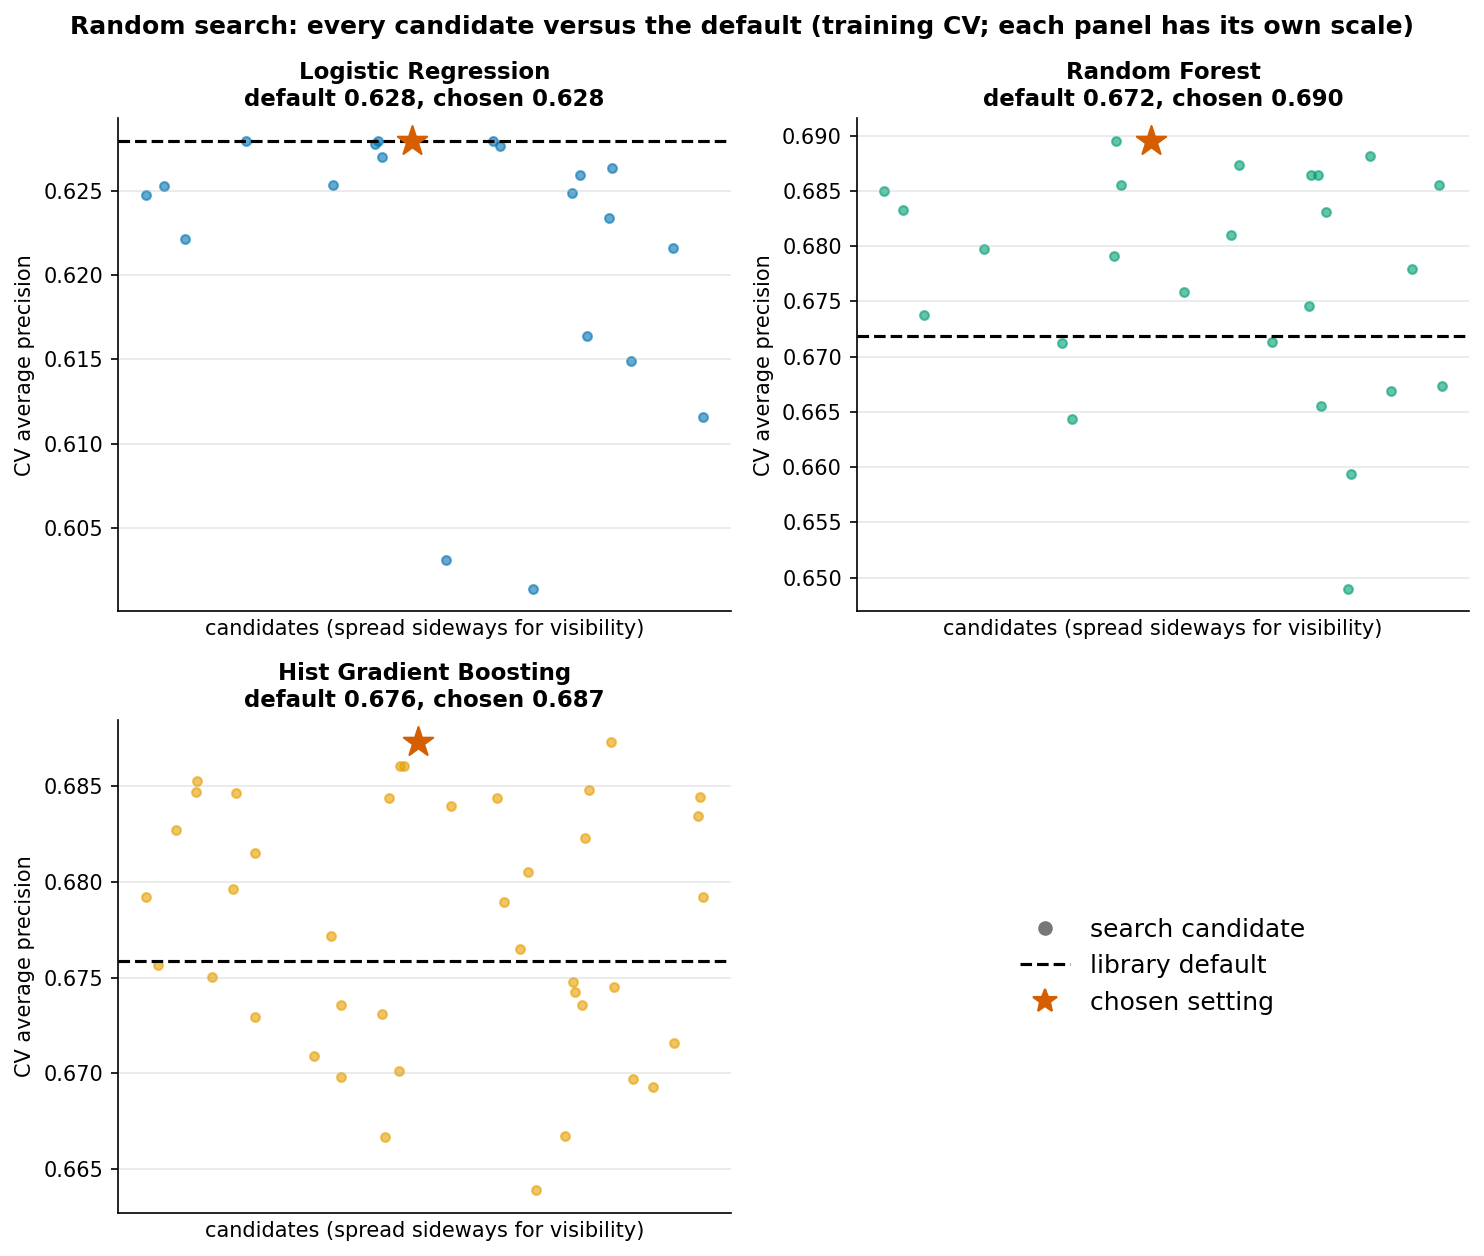

**reports/figures/fig_F_01_validation_curves.png**

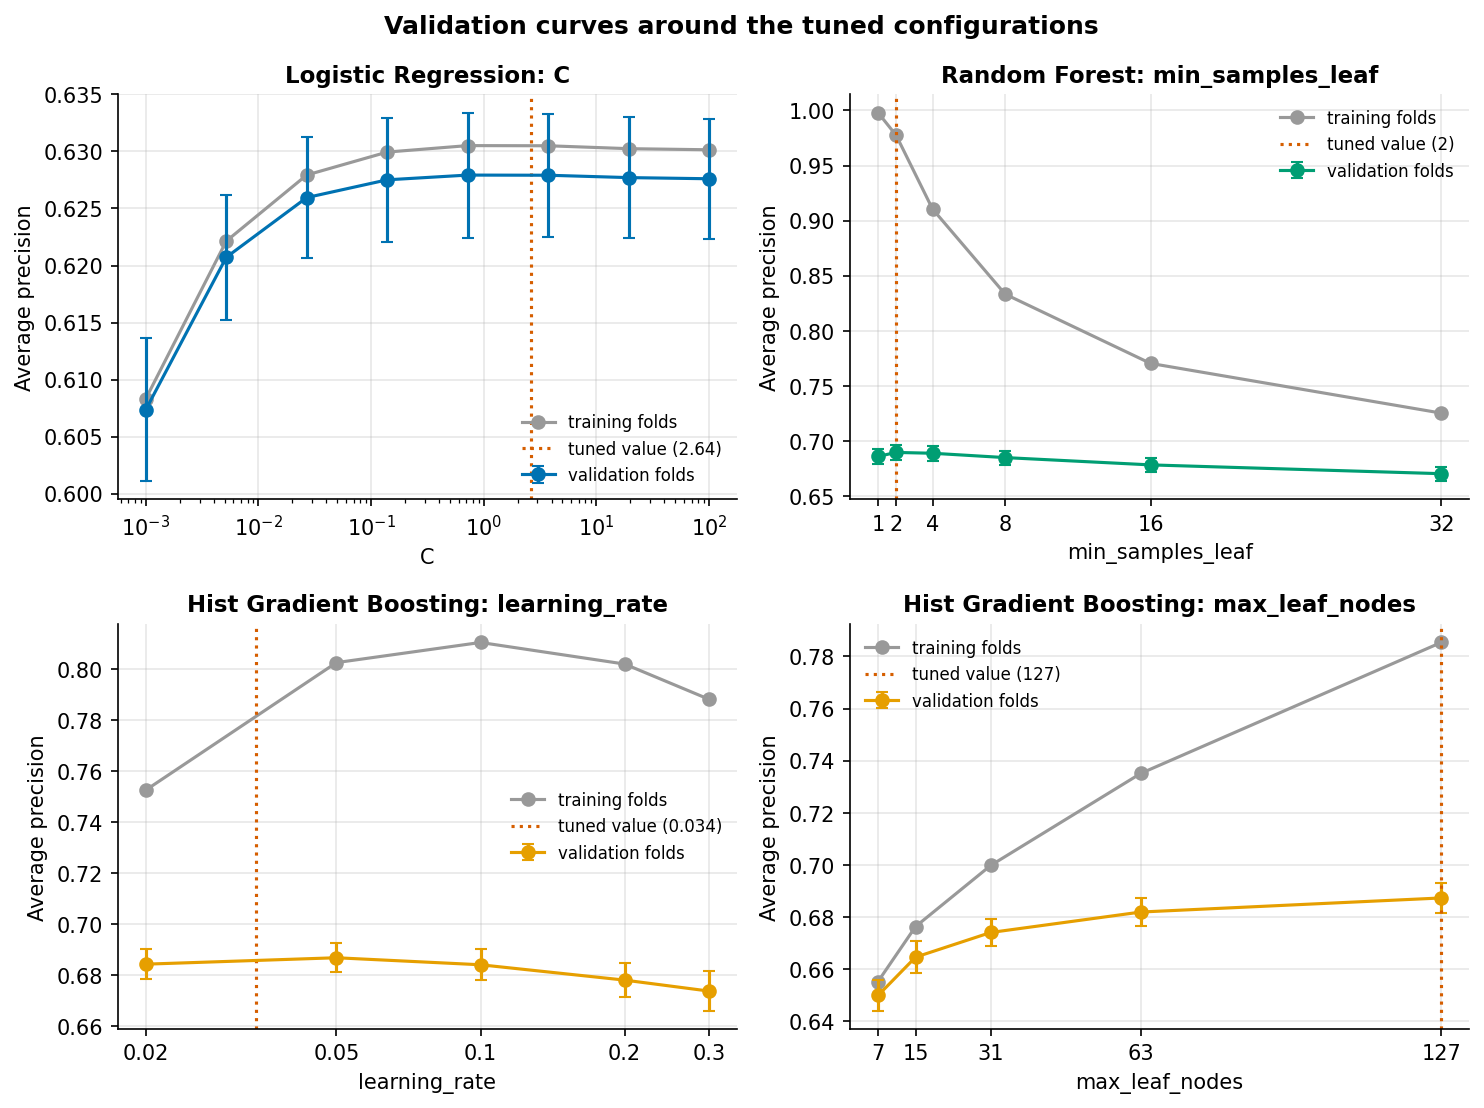

In [3]:
display(tuning[['model', 'default_pr_auc', 'tuned_pr_auc', 'improvement_pr_auc', 'improvement_ci_low', 'improvement_ci_high', 'improvement_p_value', 'candidates', 'candidates_beating_default', 'chosen', 'best_params_json', 'search_seconds']])
display(curves)
show('fig_F_00_search_summary.png', 'fig_F_01_validation_curves.png')